In [5]:
from pathlib import Path

# AuthentiScore project root
ROOT = Path(r"C:\Users\Acer\Documents\AuthentiScore")

TRAIN_DIR = ROOT / "data" / "processed" / "train_test"

print("Project root:")
print(ROOT)

print("\nTrain/Test directory:")
print(TRAIN_DIR)

print("\nFiles:")
for file in TRAIN_DIR.iterdir():
    print(file.name)

Project root:
C:\Users\Acer\Documents\AuthentiScore

Train/Test directory:
C:\Users\Acer\Documents\AuthentiScore\data\processed\train_test

Files:
scaler.pkl
X_test.csv
X_train.csv
y_test.csv
y_train.csv


In [6]:
import pandas as pd

X_train = pd.read_csv(TRAIN_DIR / "X_train.csv")
X_test = pd.read_csv(TRAIN_DIR / "X_test.csv")

y_train = pd.read_csv(TRAIN_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(TRAIN_DIR / "y_test.csv").squeeze()

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (556, 9)
X_test : (140, 9)
y_train: (556,)
y_test : (140,)


In [7]:
from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

model.fit(X_train, y_train)

print("✅ XGBoost trained.")

✅ XGBoost trained.


In [8]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("XGBoost Results")
print("-" * 35)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

XGBoost Results
-----------------------------------
Accuracy : 0.8929
Precision: 0.9104
Recall   : 0.8714
F1 Score : 0.8905
ROC-AUC  : 0.9543


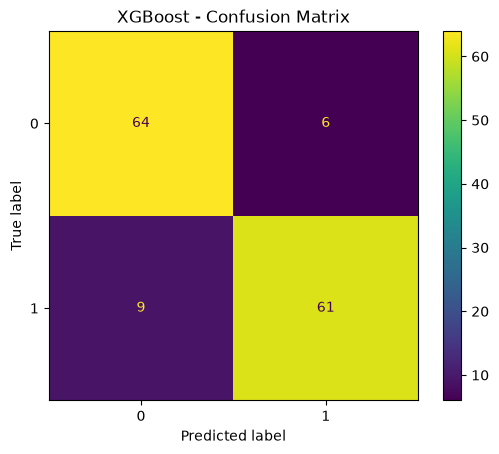

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.title("XGBoost - Confusion Matrix")
plt.show()

In [11]:
FEATURES = [
    "followers",
    "following",
    "posts",
    "bio_length",
    "has_profile_picture",
    "is_private",
    "username_digit_ratio",
    "follower_following_ratio",
    "profile_completeness"
]

importance = pd.DataFrame({
    "feature": FEATURES,
    "importance": model.feature_importances_
})

importance.sort_values(
    "importance",
    ascending=False
)

,feature,importance
2,posts,0.265349
4,has_profile_picture,0.233873
0,followers,0.127456
6,username_digit_ratio,0.114028
7,follower_following_ratio,0.113152
3,bio_length,0.082317
5,is_private,0.034120
1,following,0.029705
8,profile_completeness,0.000000


In [12]:
import joblib

MODEL_DIR = ROOT / "backend" / "trained_models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    model,
    MODEL_DIR / "xgboost.pkl"
)

print("✅ XGBoost saved.")

✅ XGBoost saved.
